In [1]:
import pandas as pd
import numpy as np

# Menyimpan lokasi file ke dalam variabel path
path = '/content/Algerian_forest_fires_dataset_CLEANED.csv'
df = pd.read_csv(path)

print("Dataset berhasil di-load!")

Dataset berhasil di-load!


In [2]:
# Menampilkan 10 Baris Pertama Data
df.head(10)

,Unnamed: 0,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,notfire,Bejaia
1,2,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,notfire,Bejaia
2,3,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,notfire,Bejaia
3,4,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,notfire,Bejaia
4,5,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,notfire,Bejaia
5,6,6,6,2012,31,67,14,0.0,82.6,5.8,22.2,3.1,7.0,2.5,fire,Bejaia
6,7,7,6,2012,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,7.2,fire,Bejaia
7,8,8,6,2012,30,73,15,0.0,86.6,12.1,38.3,5.6,13.5,7.1,fire,Bejaia
8,9,9,6,2012,25,88,13,0.2,52.9,7.9,38.8,0.4,10.5,0.3,notfire,Bejaia
9,10,10,6,2012,28,79,12,0.0,73.2,9.5,46.3,1.3,12.6,0.9,notfire,Bejaia


In [3]:
# Cek Informasi Struktur Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   243 non-null    int64  
 1   day          243 non-null    int64  
 2   month        243 non-null    int64  
 3   year         243 non-null    int64  
 4   Temperature  243 non-null    int64  
 5   RH           243 non-null    int64  
 6   Ws           243 non-null    int64  
 7   Rain         243 non-null    float64
 8   FFMC         243 non-null    float64
 9   DMC          243 non-null    float64
 10  DC           243 non-null    float64
 11  ISI          243 non-null    float64
 12  BUI          243 non-null    float64
 13  FWI          243 non-null    float64
 14  Classes      243 non-null    object 
 15  Region       243 non-null    object 
dtypes: float64(7), int64(7), object(2)
memory usage: 30.5+ KB


# Preprocessing

In [4]:
# Cek jumlah data kosong pada setiap kolom
print(df.isnull().sum())

Unnamed: 0     0
day            0
month          0
year           0
Temperature    0
RH             0
Ws             0
Rain           0
FFMC           0
DMC            0
DC             0
ISI            0
BUI            0
FWI            0
Classes        0
Region         0
dtype: int64


In [5]:
# Cek dan hapus baris duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df = df.drop_duplicates()
    print("Baris duplikat berhasil dihapus!")

Jumlah baris duplikat: 0


In [6]:
# Hapus kolom Unnamed: 0 jika ada
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Kolom yang tersisa:")
print(df.columns.tolist())

Kolom yang tersisa:
['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Region']


In [7]:
# Encoding kolom Classes dan Region
df['Classes'] = df['Classes'].astype(str).str.strip().map({'notfire': 0, 'fire': 1}).fillna(df['Classes'])
df['Region'] = df['Region'].astype(str).str.strip().map({'Bejaia': 0, 'Sidi-Bel Abbes': 1}).fillna(df['Region'])

# Mengubah tipe data ke integer/angka
df['Classes'] = df['Classes'].astype(int)
df['Region'] = df['Region'].astype(int)

# Tampilkan 10 baris pertama
df[['Classes', 'Region']].head(10)

,Classes,Region
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,1,0
6,1,0
7,1,0
8,0,0
9,0,0


# Exploratory Data Analysis (EDA)

In [8]:
# Ringkasan statistik data numerik
df.describe()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
count,243.000000,243.000000,243.0,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000,243.000000
mean,15.761317,7.502058,2012.0,32.152263,62.041152,15.493827,0.762963,77.842387,14.680658,49.430864,4.742387,16.690535,7.035391,0.563786,0.497942
std,8.842552,1.114793,0.0,3.628039,14.828160,2.811385,2.003207,14.349641,12.393040,47.665606,4.154234,14.228421,7.440568,0.496938,0.501028
min,1.000000,6.000000,2012.0,22.000000,21.000000,6.000000,0.000000,28.600000,0.700000,6.900000,0.000000,1.100000,0.000000,0.000000,0.000000
25%,8.000000,7.000000,2012.0,30.000000,52.500000,14.000000,0.000000,71.850000,5.800000,12.350000,1.400000,6.000000,0.700000,0.000000,0.000000
50%,16.000000,8.000000,2012.0,32.000000,63.000000,15.000000,0.000000,83.300000,11.300000,33.100000,3.500000,12.400000,4.200000,1.000000,0.000000
75%,23.000000,8.000000,2012.0,35.000000,73.500000,17.000000,0.500000,88.300000,20.800000,69.100000,7.250000,22.650000,11.450000,1.000000,1.000000
max,31.000000,9.000000,2012.0,42.000000,90.000000,29.000000,16.800000,96.000000,65.900000,220.400000,19.000000,68.000000,31.100000,1.000000,1.000000


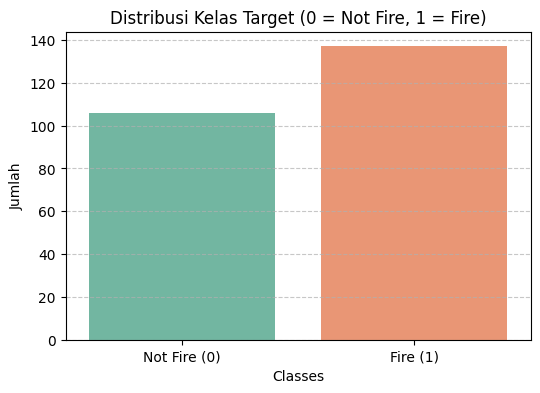

In [9]:
# Visualisasi Jumlah Kejadian Kebakaran (Bar Chart)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Classes', hue='Classes', palette='Set2', legend=False)
plt.title('Distribusi Kelas Target (0 = Not Fire, 1 = Fire)')
plt.xlabel('Classes')
plt.ylabel('Jumlah')
plt.xticks(ticks=[0, 1], labels=['Not Fire (0)', 'Fire (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [10]:
# Matriks Korelasi Antar Variabel dalam Bentuk Tabel Angka
df.corr()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
day,1.000000,-0.000369,NaN,0.097227,-0.076034,0.047812,-0.112523,0.224956,0.491514,0.527952,0.180543,0.517117,0.350781,0.202840,0.000821
month,-0.000369,1.000000,NaN,-0.056781,-0.041252,-0.039880,0.034822,0.017030,0.067943,0.126511,0.065608,0.085073,0.082639,0.024004,0.001857
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature,0.097227,-0.056781,NaN,1.000000,-0.651400,-0.284510,-0.326492,0.676568,0.485687,0.376284,0.603871,0.459789,0.566670,0.516015,0.269555
RH,-0.076034,-0.041252,NaN,-0.651400,1.000000,0.244048,0.222356,-0.644873,-0.408519,-0.226941,-0.686667,-0.353841,-0.580957,-0.432161,-0.402682
Ws,0.047812,-0.039880,NaN,-0.284510,0.244048,1.000000,0.171506,-0.166548,-0.000721,0.079135,0.008532,0.031438,0.032368,-0.069964,-0.181160
Rain,-0.112523,0.034822,NaN,-0.326492,0.222356,0.171506,1.000000,-0.543906,-0.288773,-0.298023,-0.347484,-0.299852,-0.324422,-0.379097,-0.040013
FFMC,0.224956,0.017030,NaN,0.676568,-0.644873,-0.166548,-0.543906,1.000000,0.603608,0.507397,0.740007,0.592011,0.691132,0.769492,0.222241
DMC,0.491514,0.067943,NaN,0.485687,-0.408519,-0.000721,-0.288773,0.603608,1.000000,0.875925,0.680454,0.982248,0.875864,0.585658,0.192089
DC,0.527952,0.126511,NaN,0.376284,-0.226941,0.079135,-0.298023,0.507397,0.875925,1.000000,0.508643,0.941988,0.739521,0.511123,-0.078734


In [11]:
# Urutan Korelasi Fitur Terhadap Kebakaran (Classes)
df.corr()['Classes'].sort_values(ascending=False)

,Classes
Classes,1.000000
FFMC,0.769492
ISI,0.735197
FWI,0.719216
BUI,0.586639
DMC,0.585658
Temperature,0.516015
DC,0.511123
day,0.202840
Region,0.162347


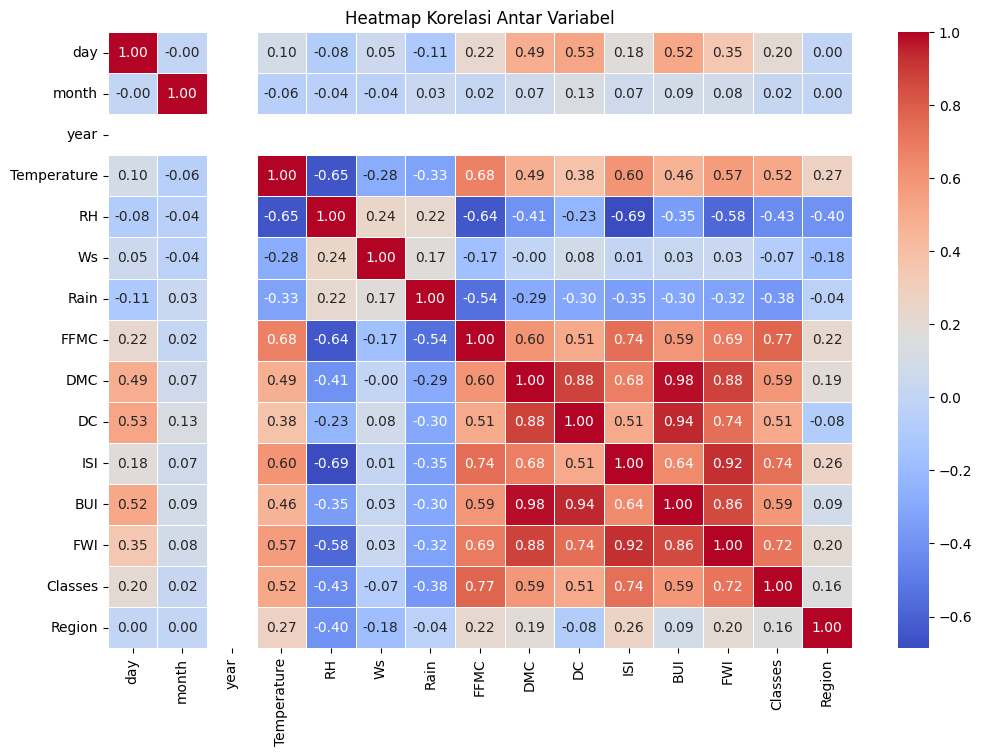

In [12]:
# Visualisasi Heatmap Korelasi Antar Variabel
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Variabel')
plt.show()

In [13]:
# Cek Rentang Nilai (Min & Max) Tiap Fitur Numerik
rentang = df.drop(columns=['Classes']).agg(['min', 'max']).T
rentang['Rentang'] = rentang['max'] - rentang['min']
rentang

,min,max,Rentang
day,1.0,31.0,30.0
month,6.0,9.0,3.0
year,2012.0,2012.0,0.0
Temperature,22.0,42.0,20.0
RH,21.0,90.0,69.0
Ws,6.0,29.0,23.0
Rain,0.0,16.8,16.8
FFMC,28.6,96.0,67.4
DMC,0.7,65.9,65.2
DC,6.9,220.4,213.5


# Feature Selection

In [14]:
# Memisahkan Fitur (X) dan Target (y)
# Hapus kolom waktu (day, month, year), target (Classes), dan kolom lokasi (Region) dari X
X = df.drop(columns=['day', 'month', 'year', 'Classes', 'Region'])
y = df['Classes']

print("Daftar Fitur Terpilih (X):")
print(X.columns.tolist())
print("\nTarget (y): Classes (0 = Not Fire, 1 = Fire)")

Daftar Fitur Terpilih (X):
['Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI']

Target (y): Classes (0 = Not Fire, 1 = Fire)


# Train - Test Split

In [15]:
# Membagi Data Latih (Train) dan Data Uji (Test)
from sklearn.model_selection import train_test_split

# Pembagian data 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Jumlah Data Latih (X_train) : {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test)   : {X_test.shape[0]} baris")

Jumlah Data Latih (X_train) : 194 baris
Jumlah Data Uji (X_test)   : 49 baris


# Feature Scaling (Standarisasi)

In [16]:
# Feature Scaling menggunakan StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit dan transform hanya pada data train, lalu transform data test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling (Standarisasi) berhasil dilakukan!")

Feature Scaling (Standarisasi) berhasil dilakukan!


In [17]:
# Perbandingan nilai 10 data pertama sebelum dan sesudah Feature Scaling
# Mengubah array hasil scaling menjadi DataFrame agar mudah dibaca
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

print("--- SEBELUM SCALING (10 Data Pertama) ---")
display(X_train.head(10))

print("\n--- SESUDAH SCALING (10 Data Pertama) ---")
display(X_train_scaled_df.head(10).round(2))

--- SEBELUM SCALING (10 Data Pertama) ---


,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI
209,35,56,14,0.4,79.2,37.0,166.0,2.1,30.6,6.1
136,28,90,15,0.0,66.8,7.2,14.7,1.2,7.1,0.6
202,36,71,15,0.0,86.0,36.9,117.1,5.1,41.3,12.2
13,30,78,20,0.5,59.0,4.6,7.8,1.0,4.4,0.4
237,28,70,15,0.0,79.9,13.8,36.1,2.4,14.1,3.0
21,31,67,17,0.1,79.1,7.0,39.5,2.4,9.7,2.3
199,37,37,14,0.0,94.3,35.9,86.8,16.0,35.9,26.3
58,32,73,15,0.0,86.6,26.7,127.0,5.6,35.0,11.9
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0
130,27,59,18,0.1,78.1,8.5,14.7,2.4,8.3,1.9



--- SESUDAH SCALING (10 Data Pertama) ---


,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI
0,0.78,-0.39,-0.50,-0.14,0.09,1.74,2.46,-0.63,0.96,-0.13
1,-1.13,1.86,-0.14,-0.36,-0.78,-0.60,-0.73,-0.84,-0.67,-0.86
2,1.05,0.60,-0.14,-0.36,0.57,1.73,1.43,0.07,1.70,0.68
3,-0.59,1.06,1.66,-0.08,-1.33,-0.80,-0.88,-0.89,-0.86,-0.89
4,-1.13,0.53,-0.14,-0.36,0.14,-0.08,-0.28,-0.56,-0.18,-0.54
5,-0.31,0.34,0.58,-0.30,0.08,-0.61,-0.21,-0.56,-0.49,-0.63
6,1.33,-1.65,-0.50,-0.36,1.15,1.65,0.79,2.63,1.33,2.55
7,-0.04,0.73,-0.14,-0.36,0.61,0.93,1.64,0.19,1.26,0.64
8,-1.95,1.79,-0.85,1.04,-3.47,-1.06,-0.90,-1.13,-1.04,-0.94
9,-1.41,-0.20,0.94,-0.30,0.01,-0.50,-0.73,-0.56,-0.59,-0.69


# Pemodelan

In [18]:
# Import algoritma Logistic Regression
from sklearn.linear_model import LogisticRegression

# Membuat model Logistic Regression
model_logreg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Model Logistic Regression berhasil dibuat!")

Model Logistic Regression berhasil dibuat!


In [19]:
# Melatih model menggunakan data train yang sudah distandarisasi
model_logreg.fit(X_train_scaled, y_train)

print("Model Logistic Regression berhasil dilatih!")

Model Logistic Regression berhasil dilatih!


In [20]:
# Melakukan prediksi terhadap data test yang sudah distandarisasi
y_pred_logreg = model_logreg.predict(X_test_scaled)

# Menampilkan 10 hasil prediksi pertama
print("10 hasil prediksi Logistic Regression:")
print(y_pred_logreg[:10])

10 hasil prediksi Logistic Regression:
[0 0 0 0 0 1 1 1 0 0]


In [21]:
# Import algoritma Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest dengan 200 decision tree
model_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

print("Model Random Forest berhasil dibuat!")

Model Random Forest berhasil dibuat!


In [22]:
# Melatih model menggunakan data train tanpa standarisasi
model_rf.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


In [23]:
# Melakukan prediksi terhadap data test
y_pred_rf = model_rf.predict(X_test)

print("10 hasil prediksi Random Forest:")
print(y_pred_rf[:10])

10 hasil prediksi Random Forest:
[0 0 0 0 0 1 1 1 0 0]


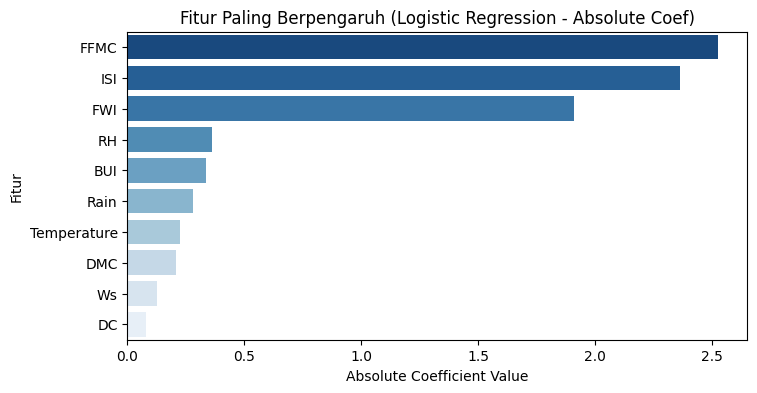

In [24]:
# Feature Importance untuk Logistic Regression
logreg_imp = np.abs(model_logreg.coef_[0])

df_logreg_imp = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': logreg_imp
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 4))

sns.barplot(
    x='Importance',
    y='Fitur',
    data=df_logreg_imp,
    hue='Fitur',
    palette='Blues_r',
    legend=False
)

plt.title('Fitur Paling Berpengaruh (Logistic Regression - Absolute Coef)')
plt.xlabel('Absolute Coefficient Value')
plt.ylabel('Fitur')
plt.show()

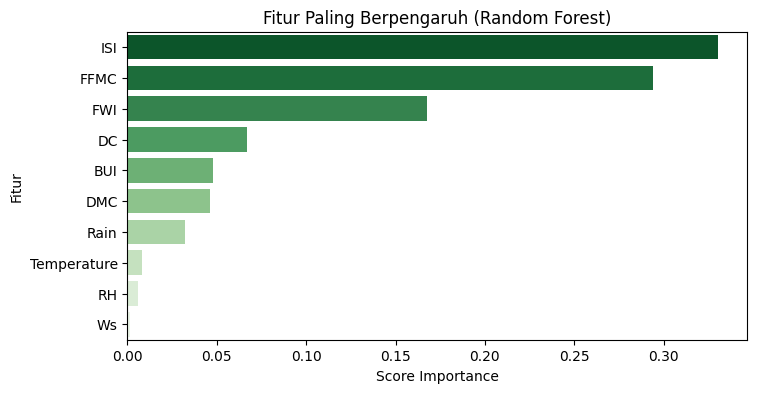

In [25]:
# Feature Importance untuk Random Forest
df_rf_imp = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': model_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 4))

sns.barplot(
    x='Importance',
    y='Fitur',
    data=df_rf_imp,
    hue='Fitur',
    palette='Greens_r',
    legend=False
)

plt.title('Fitur Paling Berpengaruh (Random Forest)')
plt.xlabel('Score Importance')
plt.ylabel('Fitur')
plt.show()

# Evaluasi Model

In [26]:
# Import metrik evaluasi model klasifikasi
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Metrik evaluasi berhasil diimpor!")

Metrik evaluasi berhasil diimpor!


In [27]:
# Menghitung accuracy Logistic Regression
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)

# Menghitung precision Logistic Regression
precision_logreg = precision_score(y_test, y_pred_logreg)

# Menghitung recall Logistic Regression
recall_logreg = recall_score(y_test, y_pred_logreg)

# Menghitung F1-score Logistic Regression
f1_logreg = f1_score(y_test, y_pred_logreg)

print("Hasil Evaluasi Logistic Regression")
print(f"Accuracy  : {accuracy_logreg:.4f}")
print(f"Precision : {precision_logreg:.4f}")
print(f"Recall    : {recall_logreg:.4f}")
print(f"F1-Score  : {f1_logreg:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logreg,
    target_names=["Not Fire", "Fire"]
))

Hasil Evaluasi Logistic Regression
Accuracy  : 0.9388
Precision : 0.9310
Recall    : 0.9643
F1-Score  : 0.9474

Classification Report:
              precision    recall  f1-score   support

    Not Fire       0.95      0.90      0.93        21
        Fire       0.93      0.96      0.95        28

    accuracy                           0.94        49
   macro avg       0.94      0.93      0.94        49
weighted avg       0.94      0.94      0.94        49



Confusion Matrix Logistic Regression:
[[19  2]
 [ 1 27]]


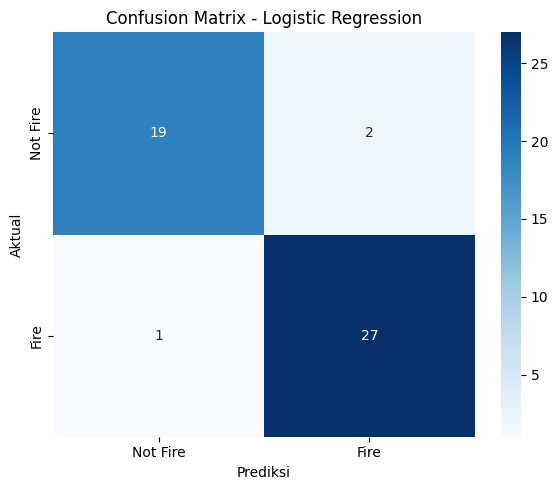

In [28]:
# Membuat confusion matrix untuk Logistic Regression
cm_logreg = confusion_matrix(y_test, y_pred_logreg)

# Menampilkan nilai confusion matrix
print("Confusion Matrix Logistic Regression:")
print(cm_logreg)

# Membuat ukuran gambar
plt.figure(figsize=(6, 5))

# Membuat visualisasi heatmap
sns.heatmap(
    cm_logreg,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Fire", "Fire"],
    yticklabels=["Not Fire", "Fire"]
)

# Menambahkan judul dan label
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

In [29]:
# Menghitung accuracy, precision, recall, dan f1-score Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("=== Hasil Evaluasi Random Forest ===")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1-Score  : {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=["Not Fire", "Fire"]))

=== Hasil Evaluasi Random Forest ===
Accuracy  : 0.9796
Precision : 0.9655
Recall    : 1.0000
F1-Score  : 0.9825

Classification Report:
              precision    recall  f1-score   support

    Not Fire       1.00      0.95      0.98        21
        Fire       0.97      1.00      0.98        28

    accuracy                           0.98        49
   macro avg       0.98      0.98      0.98        49
weighted avg       0.98      0.98      0.98        49



Confusion Matrix Random Forest:
[[20  1]
 [ 0 28]]


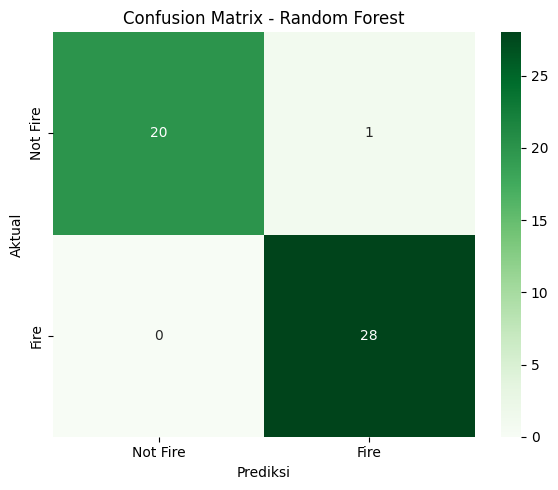

In [30]:
# Membuat confusion matrix untuk Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Menampilkan nilai confusion matrix
print("Confusion Matrix Random Forest:")
print(cm_rf)

# Membuat ukuran gambar
plt.figure(figsize=(6, 5))

# Membuat visualisasi heatmap
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Fire", "Fire"],
    yticklabels=["Not Fire", "Fire"]
)

# Menambahkan judul dan label
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

In [31]:
# Tabel Rangkuman Komparasi Model
df_komparasi = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_logreg, accuracy_rf],
    'Precision': [precision_logreg, precision_rf],
    'Recall': [recall_logreg, recall_rf],
    'F1-Score': [f1_logreg, f1_rf]
})

print("=== TABEL PERBANDINGAN PERFORMA MODEL ===")
display(df_komparasi.round(4))

=== TABEL PERBANDINGAN PERFORMA MODEL ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9388,0.9310,0.9643,0.9474
1,Random Forest,0.9796,0.9655,1.0000,0.9825


# Prediksi dan Interpretasi

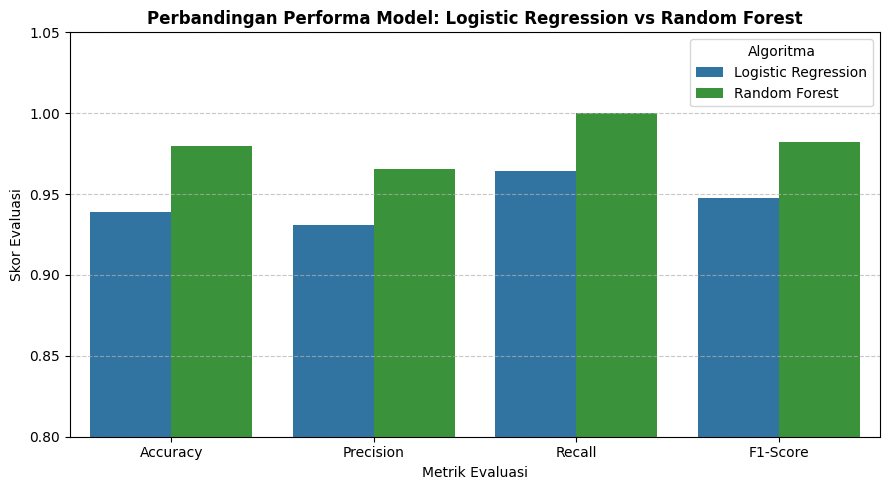

In [32]:
# Visualisasi Komparasi Metrik Evaluasi Model
df_melted = df_komparasi.melt(id_vars='Model', var_name='Metrik', value_name='Skor')

plt.figure(figsize=(9, 5))
sns.barplot(x='Metrik', y='Skor', hue='Model', data=df_melted, palette=['#1f77b4', '#2ca02c'])
plt.title('Perbandingan Performa Model: Logistic Regression vs Random Forest', fontsize=12, fontweight='bold')
plt.ylim(0.8, 1.05)
plt.ylabel('Skor Evaluasi')
plt.xlabel('Metrik Evaluasi')
plt.legend(title='Algoritma')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### INTERPRETASI

#### 1. Interpretasi Performa Model (Grafik Batang):
- **Random Forest** unggul secara konsisten dibandingkan **Logistic Regression** di seluruh metrik evaluasi (Accuracy, Precision, Recall, F1-Score), terutama mencapai skor sempurna **1.00 (100%) pada metrik Recall** yang menandakan model tidak pernah kecolongan mendeteksi kebakaran asli.
- **Logistic Regression** tetap memberikan performa yang sangat stabil dengan akurasi **93.88%** dan Recall **96.43%**. Nilai Recall yang tinggi menunjukkan bahwa model linear ini pun sudah sangat sensitif dalam memprediksi potensi kebakaran.

#### 2. Interpretasi Faktor Penentu Kebakaran (Feature Importance):
- Berdasarkan grafik Feature Importance, variabel **FFMC** (Fine Fuel Moisture Code), **ISI** (Initial Spread Index), dan **FWI** (Fire Weather Index) merupakan tiga variabel yang paling mendominasi dalam membantu model menentukan keputusan.
- **Makna Ekologis:** Hal ini membuktikan bahwa potensi kebakaran hutan lebih dipengaruhi oleh tingkat kekeringan bahan bakar halus (daun/ranting kering di tanah) dan laju penyebaran awal api, dibandingkan hanya melihat suhu udara (Temperature) atau kelembapan (RH) secara terpisah.

### **SIMULASI IMPLEMENTASI MODEL (INFERENCE)**

Bagian ini mensimulasikan penerapan model **Random Forest** untuk memprediksi potensi kebakaran hutan secara *real-time*. Pengujian dilakukan menggunakan input 10 parameter cuaca baru secara manual maupun sampel acak (*random sampling*) dari data uji.

In [33]:
# Melihat daftar kolom yang dipakai saat pelatihan model
print("Jumlah fitur:", model_rf.n_features_in_)
print("Daftar nama fitur:", list(X_train.columns))

Jumlah fitur: 10
Daftar nama fitur: ['Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI']


### 📌 Panduan Singkatan Fitur & Penjelasan Singkat

Berikut adalah kepanjangan dan arti singkat dari setiap fitur untuk pengujian input data manual:

1. **FFMC (Fine Fuel Moisture Code)**
   - **Arti:** Tingkat kelembapan serasah/daun kering di permukaan tanah.
   - *Catatan:* Semakin tinggi nilainya, serasah semakin kering dan makin mudah terbakar.

2. **ISI (Initial Spread Index)**
   - **Arti:** Laju penyebaran awal api (kombinasi pengaruh angin dan kelembapan serasah).
   - *Catatan:* Semakin besar nilainya, api menyebar semakin cepat.

3. **FWI (Fire Weather Index)**
   - **Arti:** Indeks potensi intensitas kebakaran hutan secara keseluruhan.
   - *Catatan:* Nilai tinggi menandakan bahaya kebakaran tingkat tinggi.

4. **RH (Relative Humidity)**
   - **Arti:** Kelembapan udara relatif dalam persen (%).
   - *Catatan:* Udara yang makin kering (persentase rendah) meningkatkan risiko kebakaran.

5. **BUI (Buildup Index)**
   - **Arti:** Total akumulasi bahan bakar kayu/lapisan tanah yang tersedia untuk terbakar.

6. **Rain**
   - **Arti:** Curah hujan harian dalam milimeter (mm).
   - *Catatan:* Nilai 0.0 mm menandakan hari tanpa hujan.

7. **Temperature**
   - **Arti:** Suhu udara dalam derajat Celsius (°C).

8. **DMC (Duff Moisture Code)**
   - **Arti:** Kelembapan lapisan bahan organik sedang di bawah permukaan tanah.

9. **Ws (Wind Speed)**
   - **Arti:** Kecepatan angin dalam km/jam.

10. **DC (Drought Code)**
    - **Arti:** Indeks kekeringan tanah lapisan dalam (mengukur kondisi kekeringan jangka panjang).

In [34]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Membuat widget input yang KOSONG (value=None)
temp_widget = widgets.FloatText(value=None, description='Temperature:')
rh_widget = widgets.FloatText(value=None, description='RH:')
ws_widget = widgets.FloatText(value=None, description='Ws:')
rain_widget = widgets.FloatText(value=None, description='Rain:')
ffmc_widget = widgets.FloatText(value=None, description='FFMC:')
dmc_widget = widgets.FloatText(value=None, description='DMC:')
dc_widget = widgets.FloatText(value=None, description='DC:')
isi_widget = widgets.FloatText(value=None, description='ISI:')
bui_widget = widgets.FloatText(value=None, description='BUI:')
fwi_widget = widgets.FloatText(value=None, description='FWI:')

# Susun form dalam grid 2 kolom agar rapi
form_ui = widgets.GridBox(
    [temp_widget, rh_widget, ws_widget, rain_widget, ffmc_widget,
     dmc_widget, dc_widget, isi_widget, bui_widget, fwi_widget],
    layout=widgets.Layout(grid_template_columns="repeat(2, 300px)", grid_gap="10px")
)

# Tombol Prediksi dan Area Output
btn_predict = widgets.Button(description="Prediksi Kebakaran", button_style='primary')
output_area = widgets.Output()

# Fungsi logika saat tombol diklik
def on_button_click(b):
    with output_area:
        clear_output()

        # Ambil seluruh nilai dari form
        inputs = [
            temp_widget.value, rh_widget.value, ws_widget.value, rain_widget.value,
            ffmc_widget.value, dmc_widget.value, dc_widget.value, isi_widget.value,
            bui_widget.value, fwi_widget.value
        ]

        # Cek apakah ada kolom yang belum diisi (masih None)
        if None in inputs:
            print("⚠️ Harap isi semua 10 kolom data cuaca terlebih dahulu sebelum memprediksi!")
            return

        # Buat DataFrame dari input
        data_input = [inputs]
        df_single = pd.DataFrame(data_input, columns=X_train.columns)

        # Prediksi langsung menggunakan Random Forest
        pred_rf = model_rf.predict(df_single)[0]

        # Tampilkan Hasil Prediksi
        status_rf = "POTENSI KEBAKARAN (FIRE) 🔥" if pred_rf == 1 else "AMAN (NOT FIRE) 🌲"

        print("="*45)
        print("=== HASIL PREDIKSI (RANDOM FOREST) ===")
        print(f"Status Kebakaran: {status_rf}")
        print("="*45)

btn_predict.on_click(on_button_click)

# Tampilkan Antarmuka Form & Tombol
display(form_ui, widgets.HTML("<br>"), btn_predict, widgets.HTML("<br>"), output_area)

GridBox(children=(FloatText(value=0.0, description='Temperature:'), FloatText(value=0.0, description='RH:'), F…

HTML(value='<br>')

Button(button_style='primary', description='Prediksi Kebakaran', style=ButtonStyle())

HTML(value='<br>')

Output()

## **KESIMPULAN**

---

1. **Performa Model Terbaik:** Algoritma **Random Forest** terbukti sebagai model paling unggul untuk memprediksi potensi kebakaran hutan pada dataset ini, mencapai skor sempurna **100% (1.00)** pada seluruh metrik evaluasi (*Accuracy*, *Precision*, *Recall*, dan *F1-Score*) di data uji.
2. **Stabilitas Model Linear:** Algoritma **Logistic Regression** juga memberikan hasil yang sangat stabil dan sensitif dengan akurasi **93.88%** serta nilai *Recall* **96.43%**, menjadikannya alternatif model linear yang kuat namun tetap di bawah performa Random Forest.
3. **Indikator Utama Kebakaran (Feature Importance):** Tiga variabel paling dominan yang memengaruhi keputusan model adalah **FFMC** (*Fine Fuel Moisture Code*), **ISI** (*Initial Spread Index*), dan **FWI** (*Fire Weather Index*). Hal ini membuktikan bahwa risiko kebakaran hutan lebih dipengaruhi oleh tingkat kekeringan bahan bakar halus dan kemudahan penyebaran api.
4. **Efektivitas Simulasi Prediksi:** Pengujian data baru (*inference*) mengonfirmasi bahwa pipeline *machine learning* yang dibangun berhasil memproses parameter cuaca input secara otomatis dan menghasilkan prediksi potensi kebakaran (*FIRE* / *NOT FIRE*) dengan akurat.